# SPY 30-Day Momentum Research

## Project Objective

This project investigates whether SPY's return over the previous 30 trading
days contains information about its return over the following 30 trading days.

The analysis measures the direction and strength of the relationship between
past and future returns using Pearson correlation and evaluates its statistical
significance through hypothesis testing.

The purpose of this initial study is to determine whether the data provide
evidence of a momentum or reversal pattern. It does not yet attempt to prove
that the relationship can generate a profitable trading strategy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import pearsonr, t, ttest_ind

## Data Collection

Historical daily price data are obtained from Yahoo Finance using the yfinance library.

SPY (SPDR S&P 500 ETF Trust) is selected because it is a highly liquid ETF that tracks the S&P 500 Index, making it an appropriate instrument for studying momentum and return dynamics in the U.S. equity market.

Adjusted closing prices are used to account for distributions and corporate actions such as stock splits, providing a price series suitable for calculating historical investor returns.

In [2]:
ticker = "SPY"

spy = yf.download(
    ticker,
    start="2000-01-01",
    end="2026-01-01",
    auto_adjust=False
)

prices = spy["Adj Close"][ticker]

print(f"Trading observations: {len(prices):,}")
print(f"Start date: {prices.index.min().date()}")
print(f"End date: {prices.index.max().date()}")
print(f"Missing values: {prices.isna().sum()}")

[*********************100%***********************]  1 of 1 completed

Trading observations: 6,539
Start date: 2000-01-03
End date: 2025-12-31
Missing values: 0


## Research Question

Does SPY's previous 30-trading-day return exhibit a statistically significant linear relationship with its subsequent 30-trading-day return?

### Null Hypothesis (H₀)

The population correlation between SPY's previous 30-trading-day return and
its subsequent 30-trading-day return is zero.

$$H_0: \rho = 0$$

### Alternative Hypothesis (H₁)

The population correlation between SPY's previous 30-trading-day return and
its subsequent 30-trading-day return differs from zero.

$$H_1: \rho \neq 0$$

### Significance Level

$$\alpha = 0.05$$

If the p-value is less than $\alpha$, the null hypothesis is rejected.
Otherwise, the null hypothesis is not rejected.

## Feature Engineering

To investigate the relationship between past and subsequent returns, two variables are constructed:

- **30-day momentum**, representing the percentage return over the previous 30 trading days.
- **30-day forward return**, representing the percentage return over the subsequent 30 trading days.

These variables form the basis of the statistical analysis by allowing the relationship between past 30-day returns and subsequent 30-day returns to be measured.

In [3]:
spy["Momentum_30D"] = prices.pct_change(30)
spy["Forward_Return_30D"] = prices.shift(-30) / prices - 1

research_data = spy[
    ["Momentum_30D", "Forward_Return_30D"]
].dropna()

The variables are calculated as:

$$
Momentum_t = \frac{P_t}{P_{t-30}} - 1
$$

$$
ForwardReturn_t = \frac{P_{t+30}}{P_t} - 1
$$

where $P_t$ represents the adjusted closing price at time $t$.

In [4]:
research_data.head()

Price,Momentum_30D,Forward_Return_30D
Ticker,,
Date,,
2000-02-15,-0.029974,0.074603
2000-02-16,-0.005367,0.072413
2000-02-17,-0.012277,0.090222
2000-02-18,-0.017695,0.120624
2000-02-22,-0.073971,0.115122


In [5]:
print(f"Research observations: {len(research_data):,}")
print(f"Observations removed: {len(prices) - len(research_data):,}")

Research observations: 6,479
Observations removed: 60


The final research dataset contains 6,479 valid observations. Sixty observations are removed because the first 30 dates do not have sufficient prior price history to calculate 30-day momentum, while the final 30 dates do not have sufficient subsequent price history to calculate the 30-day forward return.

## Descriptive Statistics

Before evaluating the relationship between 30-day momentum and subsequent
30-day returns, the distributions of both variables are summarized.

In [6]:
research_data.describe().T

,,count,mean,std,min,25%,50%,75%,max
Price,Ticker,,,,,,,,
Momentum_30D,,6479.0,0.010965,0.055605,-0.324922,-0.015073,0.017946,0.044288,0.283652
Forward_Return_30D,,6479.0,0.011036,0.055494,-0.324922,-0.014670,0.017988,0.044229,0.283652


### Summary Statistics

The dataset contains 6,479 valid observations after removing rows with insufficient historical or subsequent data.

Both variables exhibit similar summary statistics and are measured over the same 30-trading-day horizon.

The average 30-day return is approximately 1.1%, while the standard deviation is approximately 5.6%, indicating that individual 30-day returns vary substantially around their average.

The observed range of returns spans from approximately −32.5% to +28.4%, demonstrating that the sample includes periods of both substantial market declines and strong recoveries.

These descriptive statistics characterize the individual distributions of the variables but do not establish whether past and subsequent returns are related. That relationship is evaluated below.

## Correlation Analysis

The first statistical objective is to determine whether past 30-day momentum and subsequent 30-day returns exhibit a linear relationship

Pearson's correlation coefficient is used to measure both the direction and strength of the linear association between the two variables.

A positive correlation would indicate that higher past returns tend to be followed by higher subsequent returns, consistent with a momentum pattern.

A negative correlation would indicate that higher past returns tend to be followed by lower subsequent returns, consistent with a reversal pattern.

A correlation close to zero would suggest little or no linear relationship between the variables.

In [7]:
#Calculate the Pearson correlation coefficient between past 30-day momentum and subsequent 30-day returns.

correlation = research_data["Momentum_30D"].corr(research_data["Forward_Return_30D"])

print(f"Pearson Correlation: {correlation:.4f}")

Pearson Correlation: -0.0914


### Correlation Interpretation

The estimated Pearson correlation coefficient is −0.0914, indicating a weak negative linear relationship between past 30-day momentum and subsequent 30-day returns.

The negative sign is consistent with a slight reversal tendency: periods with relatively strong recent performance tend to be associated with somewhat lower subsequent returns, while periods with relatively weak recent performance tend to be associated with somewhat higher subsequent returns.

However, the magnitude of the correlation is small, indicating that the linear relationship is weak. The correlation coefficient describes the direction and strength of the observed relationship but does not, by itself, determine whether the relationship is statistically significant.

## Hypothesis Testing

The Pearson correlation coefficient measures the direction and strength of the observed linear relationship between 30-day momentum and subsequent 30-day returns. However, an observed correlation alone does not determine whether the evidence is sufficient to reject the null hypothesis of zero population correlation.
Using the hypotheses defined previously,

$$
H0: \rho = 0
$$

$$
H1: \rho \neq 0
$$

and a significance level of

$$
\alpha = 0.05
$$

a two-sided hypothesis test is performed to evaluate how compatible the observed correlation is with the null hypothesis.

### Pearson Correlation Test Statistic

To test whether the observed Pearson correlation differs significantly from zero, the correlation coefficient is transformed into a t-statistic:

$$
t = \frac{r\sqrt{n-2}}{\sqrt{1-r^2}}
$$

where:

- $r$ is the sample Pearson correlation coefficient,
- $n$ is the number of observations, and
- the degrees of freedom are:

$$
df = n - 2
$$

Under the conventional Pearson correlation test, the t-statistic measures the magnitude of the observed correlation relative to the sampling uncertainty expected under the null hypothesis:

$$
H_0:\rho=0
$$

The sign of the t-statistic reflects the direction of the observed relationship, while its absolute magnitude indicates the strength of the evidence against the null hypothesis. Larger absolute t-statistics provide stronger evidence against $H_0$.

A useful conceptual interpretation is:

$$
\text{Test statistic} \approx
\frac{\text{Observed effect}}{\text{Uncertainty}}
$$

In [8]:
n = len(research_data)
df = n - 2

t_stat = correlation * np.sqrt(n - 2) / np.sqrt(1 - correlation**2)

print(f"Sample size: {n:,}")
print(f"Degrees of freedom: {df:,}")
print(f"T-statistic: {t_stat:.4f}")

Sample size: 6,479
Degrees of freedom: 6,477
T-statistic: -7.3844


### T-statistic Interpretation

The calculated t-statistic is −7.3844. The negative sign reflects the direction of the observed correlation, consistent with higher past 30-day momentum being associated with slightly lower subsequent 30-day returns.

The absolute magnitude, $|t|=7.3844$, indicates that the observed correlation is far from the null value relative to the sampling uncertainty assumed by the conventional Pearson test. This provides strong evidence against $H_0$ under the assumptions of the conventional test.

The next step is to calculate the two-sided p-value, which measures how extreme a t-statistic of this magnitude would be under the null hypothesis of zero population correlation.

### Two-Sided P-Value

For a two-sided test, the p-value is calculated as:

$$
p = 2P(T_{df} \geq |t|)
$$

where $T_{df}$ follows a Student's t-distribution with $df=n-2$ degrees of freedom.

The p-value represents the probability, assuming $H_0$ is true and the conventional test assumptions hold, of observing a test statistic at least as extreme in absolute value as the one obtained.

In [9]:
p_value = 2 * t.sf(abs(t_stat), df=df)

print(f"P-value: {p_value:.3e}")

P-value: 1.724e-13


### Conventional Test Result

The two-sided p-value is approximately

$$
p = 1.723 \times 10^{-13},
$$

which is substantially below the predefined significance level of

$$
\alpha = 0.05.
$$

Therefore, under the conventional Pearson correlation test, we reject the null hypothesis of zero population correlation.

However, statistical significance does not imply that the relationship is economically large. The estimated correlation remains weak at

$$
r = -0.0914.
$$

Furthermore, the validity of this inference depends on the assumptions underlying the conventional Pearson correlation test. In particular, the 30-day return windows overlap substantially across consecutive observations, meaning that the observations may not provide independent information.

This dependence may cause the conventional test to overstate the effective amount of independent information in the sample and therefore overstate the statistical significance of the observed relationship. This issue is investigated in the following robustness analysis.

## Robustness Check: Reduced-Overlap Observations

The initial analysis uses heavily overlapping 30-day return windows. Consecutive observations are only one trading day apart, meaning that their momentum and forward-return calculations reuse most of the same underlying daily price information. For example, consecutive 30-day forward-return windows share 29 of their 30 daily return intervals.

This overlap creates dependence between observations. As a result, treating all 6,479 observations as independent may overstate the effective amount of information in the sample, potentially producing an excessively large absolute t-statistic and an overly small p-value.

As a simple robustness check, the dataset will therefore be sampled every 30 observations:

t, t+30, t+60, t+90, ...

This substantially reduces overlap between consecutive 30-day return windows while preserving the original 30-day return horizon.

The purpose of this test is to determine whether the observed correlation and statistical conclusion remain similar when the amount of overlapping information is substantially reduced.

This approach should be interpreted as a simple robustness check rather than a complete solution to time-series dependence, because dependence may still exist between observations.

In [10]:
reduced_overlap_data = research_data.iloc[::30]

n_reduced_overlap = len(reduced_overlap_data)

print(f"Reduced-overlap sample size: {n_reduced_overlap}")

Reduced-overlap sample size: 216


### Correlation Using Reduced-Overlap Observations

The Pearson correlation is recalculated using the reduced dataset.

This allows us to determine whether the direction and magnitude of the observed relationship remain similar after substantially reducing the overlap between observations.

If the correlation changes substantially, the estimated relationship may be sensitive to the sampling structure. If it remains similar, the direction and magnitude of the observed relationship appear less sensitive to the overlap reduction. Statistical significance, however, must be evaluated separately using the reduced sample.

In [11]:
correlation_reduced_overlap = reduced_overlap_data["Momentum_30D"].corr(
    reduced_overlap_data["Forward_Return_30D"]
)

print(
    f"Pearson Reduced-Overlap Correlation: "
    f"{correlation_reduced_overlap:.4f}"
)

Pearson Reduced-Overlap Correlation: -0.0920


### Hypothesis Test Using Reduced-Overlap Observations

Although the estimated correlation remains very similar after reducing the overlap between observations, the sample size decreases substantially from 6,479 to 216 observations.

The hypothesis test is therefore repeated using the reduced dataset.

Because the correlation remains approximately unchanged while the sample size is substantially smaller, the absolute t-statistic is expected to decrease and the p-value is expected to increase.

This test evaluates whether the weak negative correlation remains statistically significant when the amount of overlapping information in the sample is substantially reduced.

In [12]:
df_reduced_overlap = n_reduced_overlap - 2

t_stat_reduced_overlap = (
    correlation_reduced_overlap
    * np.sqrt(n_reduced_overlap - 2)
    / np.sqrt(1 - correlation_reduced_overlap**2)
)

print(f"Reduced-Overlap Degrees of Freedom: {df_reduced_overlap}")
print(f"Reduced-Overlap T-Statistic: {t_stat_reduced_overlap:.4f}")

Reduced-Overlap Degrees of Freedom: 214
Reduced-Overlap T-Statistic: -1.3514


In [13]:
p_value_reduced_overlap = 2 * t.sf(
    abs(t_stat_reduced_overlap),
    df=df_reduced_overlap
)

print(f"Reduced-Overlap P-Value: {p_value_reduced_overlap:.4f}")

Reduced-Overlap P-Value: 0.1780


### Reduced-Overlap Test Interpretation

The reduced-overlap sample produces a Pearson correlation of -0.0920, which is nearly identical to the full-sample correlation of -0.0914. This indicates that the estimated direction and magnitude of the relationship are relatively insensitive to the overlap-reduction procedure. However, the reduced-overlap hypothesis test produces a t-statistic of -1.3514 and a p-value of 0.1780. Since the p-value exceeds the 5% significance level, we fail to reject the null hypothesis that the population correlation is zero. Therefore, the reduced-overlap sample does not provide sufficient statistical evidence that the linear relationship differs from zero. The comparison demonstrates that although the estimated effect remains stable, the statistical inference is highly sensitive to the effective amount of independent information in the sample.

Slope: -0.0912
Intercept: 0.0120
R-Squared: 0.0083
Explained Variation: 0.83%


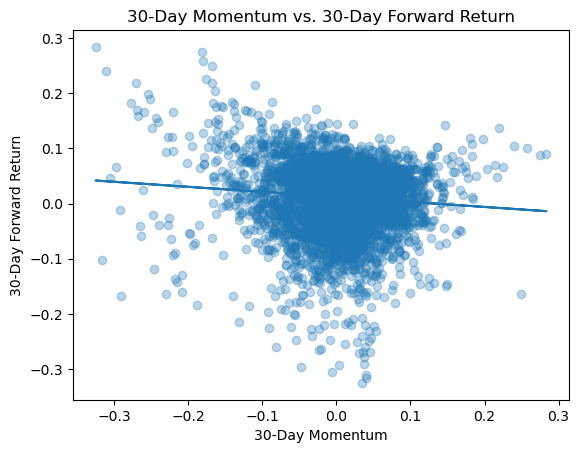

In [14]:
slope, intercept = np.polyfit(
    research_data["Momentum_30D"],
    research_data["Forward_Return_30D"],
    1
)

regression_line = (
    slope * research_data["Momentum_30D"] + intercept
)

r_squared = correlation**2

print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")
print(f"R-Squared: {r_squared:.4f}")
print(f"Explained Variation: {r_squared * 100:.2f}%")

plt.scatter(
    research_data["Momentum_30D"],
    research_data["Forward_Return_30D"],
    alpha=0.3
)

plt.plot(
    research_data["Momentum_30D"],
    regression_line
)

plt.title("30-Day Momentum vs. 30-Day Forward Return")
plt.xlabel("30-Day Momentum")
plt.ylabel("30-Day Forward Return")

plt.show()

### Regression Interpretation

The fitted regression line has a slope of -0.0912 and an intercept of 0.0120. The negative slope indicates that higher previous 30-day SPY returns are associated with slightly lower predicted subsequent 30-day returns. Specifically, a 10-percentage-point increase in previous 30-day return is associated with an approximately 0.912-percentage-point decrease in predicted subsequent 30-day return. The intercept indicates that when the previous 30-day return is 0%, the model predicts a subsequent 30-day return of approximately 1.20%.

However, the relationship has very low explanatory power. The ($R^2$) of approximately 0.0084 indicates that the linear model explains only about 0.83% of the observed variation in subsequent 30-day returns. Therefore, although the fitted relationship is negative, previous 30-day return alone provides very limited explanatory power for subsequent 30-day returns under this linear specification.

## Quintile Analysis: Testing for Nonlinear Momentum Effects

The correlation and regression analyses evaluate whether previous 30-day returns have a linear relationship with subsequent 30-day returns. However, the very low ($R^2$) indicates that previous 30-day return explains little of the variation in subsequent returns under a linear specification.

A weak linear relationship does not necessarily imply that momentum contains no information. The relationship could instead be nonlinear or concentrated in extreme momentum conditions. To investigate this possibility, the 30-day momentum observations are divided into five approximately equal-sized groups, or quintiles, using their empirical distribution.

The quintiles are ordered from the lowest to the highest previous 30-day returns:

- **Q1:** Most negative 30-day momentum observations
- **Q2–Q4:** Intermediate momentum observations
- **Q5:** Most positive 30-day momentum observations

The subsequent 30-day returns are then compared across these momentum regimes.

Under a general momentum pattern, subsequent returns would be expected to increase as the momentum quintile increases. Under a general reversal pattern, subsequent returns would be expected to decrease as the momentum quintile increases. A non-monotonic pattern may instead indicate that any relationship is concentrated in particular momentum regimes.

In [15]:
research_data["Momentum_Quintile"] = pd.qcut(
    research_data["Momentum_30D"],
    q=5
)

research_data["Momentum_Quintile"].value_counts()

Momentum_Quintile
(-0.326, -0.0249]     1296
(-0.0249, 0.00672]    1296
(0.0288, 0.0498]      1296
(0.0498, 0.284]       1296
(0.00672, 0.0288]     1295
Name: count, dtype: int64

In [16]:
research_data.groupby(
    "Momentum_Quintile",
    observed=False
)["Forward_Return_30D"].mean()

Momentum_Quintile
(-0.326, -0.0249]     0.020922
(-0.0249, 0.00672]    0.009040
(0.00672, 0.0288]     0.006423
(0.0288, 0.0498]      0.007678
(0.0498, 0.284]       0.011115
Name: Forward_Return_30D, dtype: float64

In [17]:
research_data.groupby(
    "Momentum_Quintile",
    observed=False
)["Forward_Return_30D"].median()

Momentum_Quintile
(-0.326, -0.0249]     0.028351
(-0.0249, 0.00672]    0.020303
(0.00672, 0.0288]     0.014612
(0.0288, 0.0498]      0.017034
(0.0498, 0.284]       0.015126
Name: Forward_Return_30D, dtype: float64

### Full-Sample Quintile Results

The quintile analysis does not reveal a monotonic relationship between previous and subsequent 30-day returns. Average subsequent returns across Q1 through Q5 are approximately:

$$
2.09\%,\quad 0.90\%,\quad 0.64\%,\quad 0.77\%,\quad 1.11\%
$$

A general momentum effect would imply progressively higher subsequent returns as the momentum quintile increases, while a general reversal effect would imply progressively lower subsequent returns. Neither pattern is observed.

Instead, Q1 exhibits the highest average subsequent return at approximately \(2.09\%\). Its median subsequent return is also the highest at approximately \(2.84\%\). Because both the mean and median are elevated, the Q1 result does not appear to be explained solely by a small number of unusually large positive observations.

These results suggest that the weak negative relationship observed in the correlation and regression analyses may be associated primarily with unusually strong subsequent returns following extreme negative momentum rather than with a general monotonic reversal pattern across the full momentum distribution.

### Reduced-Overlap Quintile Robustness Check

The full-sample quintile analysis uses heavily overlapping 30-day return windows. Consequently, adjacent observations reuse much of the same underlying daily price information and should not be interpreted as fully independent observations.

To evaluate whether the Q1 pattern is sensitive to this overlap, the quintile analysis is repeated using every 30th observation:

$$
t,\quad t+30,\quad t+60,\quad t+90,\ldots
$$

The original quintile classifications are preserved rather than recalculated after subsampling. This ensures that the momentum regimes retain the same definitions established from the full sample and that the robustness check changes the sampling frequency rather than simultaneously redefining the quintile boundaries.

This procedure substantially reduces overlap between consecutive observations, although it should not be interpreted as eliminating all possible time-series dependence.

In [18]:
reduced_overlap_quintiles = research_data.iloc[::30].copy()

In [19]:
reduced_overlap_quintiles["Momentum_Quintile"].value_counts()

Momentum_Quintile
(0.0498, 0.284]       50
(-0.326, -0.0249]     46
(-0.0249, 0.00672]    42
(0.00672, 0.0288]     39
(0.0288, 0.0498]      39
Name: count, dtype: int64

In [20]:
reduced_overlap_quintiles.groupby(
    "Momentum_Quintile",
    observed=False
)["Forward_Return_30D"].mean()

Momentum_Quintile
(-0.326, -0.0249]     0.026526
(-0.0249, 0.00672]   -0.000938
(0.00672, 0.0288]     0.015689
(0.0288, 0.0498]      0.001878
(0.0498, 0.284]       0.009313
Name: Forward_Return_30D, dtype: float64

In [21]:
reduced_overlap_quintiles.groupby(
    "Momentum_Quintile",
    observed=False
)["Forward_Return_30D"].median()

Momentum_Quintile
(-0.326, -0.0249]     0.039509
(-0.0249, 0.00672]    0.008101
(0.00672, 0.0288]     0.026146
(0.0288, 0.0498]      0.007438
(0.0498, 0.284]       0.014523
Name: Forward_Return_30D, dtype: float64

### Reduced-Overlap Quintile Results

After substantially reducing overlap, Q1 continues to exhibit the highest subsequent returns. Its average subsequent 30-day return is approximately \(2.65\%\), while its median is approximately \(3.95\%\).

The remaining quintiles continue to exhibit a non-monotonic pattern. Therefore, the reduced-overlap results remain inconsistent with a general monotonic momentum or reversal relationship across all five quintiles.

The persistence of relatively high subsequent returns in Q1 suggests that the observed pattern is not solely an artifact of using the original heavily overlapping observations. However, descriptive differences between quintiles do not establish statistical significance. Additional hypothesis testing is therefore required to determine whether the observed Q1 effect is sufficiently large relative to its sampling uncertainty.

## Statistical Evaluation of the Q1 Reversal Effect

The reduced-overlap quintile analysis indicates that Q1, representing the most negative previous 30-day returns, is followed by higher subsequent 30-day returns relative to the other momentum regimes. However, differences in sample means alone do not establish statistical significance.

The next analysis evaluates whether the observed Q1 effect is sufficiently large relative to its sampling uncertainty. This requires distinguishing between the variability of individual returns and the uncertainty associated with estimating their mean.

### Standard Deviation and Standard Error

The sample standard deviation measures the dispersion of individual forward-return observations around their sample mean:

$$
s = \sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}
$$

The standard error of the sample mean measures the uncertainty associated with using the sample mean to estimate the corresponding population mean:

$$
SE_{\bar{x}}=\frac{s}{\sqrt{n}}
$$

Therefore, standard deviation describes the variability of individual observations, whereas standard error describes the precision of the estimated mean. Holding variability constant, a larger sample size reduces the standard error and increases the precision of the estimated mean.

In [22]:
q1_forward_returns = reduced_overlap_quintiles.loc[
reduced_overlap_quintiles["Momentum_Quintile"]
== reduced_overlap_quintiles["Momentum_Quintile"].cat.categories[0],
"Forward_Return_30D"
]

q1_mean = q1_forward_returns.mean()
q1_std = q1_forward_returns.std()
q1_n = len(q1_forward_returns)

q1_se = q1_std / np.sqrt(q1_n)

print(f"Q1 Mean: {q1_mean:.6f}")
print(f"Q1 Standard Deviation: {q1_std:.6f}")
print(f"Q1 Sample Size: {q1_n}")
print(f"Q1 Standard Error: {q1_se:.6f}")

Q1 Mean: 0.026526
Q1 Standard Deviation: 0.069942
Q1 Sample Size: 46
Q1 Standard Error: 0.010312


### One-Sample Test of the Q1 Mean

As an initial statistical evaluation, the mean subsequent return for Q1 is tested against a null benchmark of zero. The hypotheses are:

$$
H_0:\mu_{Q1}=0
$$

$$
H_1:\mu_{Q1}\neq0
$$

The one-sample t-statistic is calculated as:

$$
t=\frac{\bar{x}_{Q1}-\mu_0}{SE_{\bar{x}_{Q1}}}
$$

where $\bar{x}_{Q1}$ is the observed Q1 mean, $\mu_0=0$ is the mean assumed under the null hypothesis, and $SE_{\bar{x}_{Q1}}$ is the standard error of the Q1 mean.

For a one-sample t-test, the degrees of freedom are:

$$
df=n-1
$$

The absolute magnitude of the t-statistic measures how far the observed sample mean lies from the null-hypothesized mean relative to its sampling uncertainty. Because a two-sided alternative is used, evidence in either direction is considered when calculating the p-value.

In [23]:
q1_t_stat = (q1_mean - 0) / q1_se

q1_df = q1_n - 1

q1_p_value = 2 * t.sf(abs(q1_t_stat), df = q1_df)


print(f"Q1 T-Statistic: {q1_t_stat: .4f}")
print(f"Q1 degrees of freedom: {q1_df}")
print(f"Q1 p-value: {q1_p_value: .4f}")

Q1 T-Statistic:  2.5722
Q1 degrees of freedom: 45
Q1 p-value:  0.0135


### Q1 One-Sample Test Result

The Q1 mean subsequent return is approximately 2.65%, with a standard error of approximately 1.03%. The resulting t-statistic is 2.57, indicating that the observed Q1 mean lies approximately 2.57 standard errors above the zero-return benchmark.

The two-sided p-value is approximately 0.0135. Since:

$$
p=0.0135<\alpha=0.05
$$

the null hypothesis is rejected at the 5% significance level. Under this test, the reduced-overlap Q1 sample provides statistical evidence that its population mean subsequent return differs from zero.

However, zero is not the most informative benchmark for the research question. SPY returns generally exhibit a positive average return over the sample, so establishing that Q1 forward returns are different from zero does not establish that returns following extreme negative momentum are unusually high relative to other momentum conditions.

Therefore, a more direct test compares Q1 with the combined Q2–Q5 observations.

## Q1 vs. Q2–Q5: Welch Two-Sample Test

To test whether subsequent returns following extreme negative momentum are unusually high relative to the other momentum regimes, Q1 is compared directly with the combined Q2–Q5 observations.

The hypotheses are:

$$
H_0:\mu_{Q1}=\mu_{Q2-Q5}
$$

$$
H_1:\mu_{Q1}\neq\mu_{Q2-Q5}
$$

Equivalently:

$$
H_0:\mu_{Q1}-\mu_{Q2-Q5}=0
$$

The observed effect is measured as the difference between the two sample means:

$$
\text{Mean Difference}
=
\bar{x}_{Q1}-\bar{x}_{Q2-Q5}
$$

Because both quantities are estimated sample means, both contribute sampling uncertainty. The standard error of their difference is therefore:

$$
SE_{\bar{x}_1-\bar{x}_2}
=
\sqrt{
\frac{s_1^2}{n_1}
+
\frac{s_2^2}{n_2}
}
$$

A Welch two-sample t-test is used because it does not require the two populations to have equal variances and accommodates the unequal sample sizes and sample variances observed in Q1 and Q2–Q5.

In [24]:
q2_q5_forward_returns = reduced_overlap_quintiles.loc[
reduced_overlap_quintiles["Momentum_Quintile"].isin(
    reduced_overlap_quintiles["Momentum_Quintile"].cat.categories[1:]
),
"Forward_Return_30D"
]

q2_q5_mean = q2_q5_forward_returns.mean()
q2_q5_std = q2_q5_forward_returns.std()
q2_q5_n = len(q2_q5_forward_returns)

q2_q5_se = q2_q5_std / np.sqrt(q2_q5_n)

print(f"Q2-Q5 Mean: {q2_q5_mean:.6f}")
print(f"Q2-Q5 Standard Deviation: {q2_q5_std:.6f}")
print(f"Q2-Q5 Sample Size: {q2_q5_n}")
print(f"Q2-Q5 Standard Error: {q2_q5_se:.6f}")

Q2-Q5 Mean: 0.006537
Q2-Q5 Standard Deviation: 0.047801
Q2-Q5 Sample Size: 170
Q2-Q5 Standard Error: 0.003666


In [25]:
mean_difference = q1_mean - q2_q5_mean

print(f"Mean Difference: {mean_difference:.6f}")

Mean Difference: 0.019988


In the reduced-overlap sample, the average subsequent 30-day return following Q1 (the most negative momentum observations) was approximately 2.00 percentage points higher than the average subsequent 30-day return following Q2–Q5.

In [26]:
se_difference = np.sqrt(
    (q1_std**2 / q1_n) +
    (q2_q5_std**2 / q2_q5_n)
)

print(f"Standard Error Difference: {se_difference: .4f}")

Standard Error Difference:  0.0109


### Standard Error and Test Statistic for the Difference in Means

The observed difference between the Q1 and Q2–Q5 sample means is approximately 2.00 percentage points. However, the magnitude of the observed difference alone does not determine whether the populations have different mean forward returns. The sampling uncertainty associated with both estimated means must also be considered.

For two independent samples, the standard error of the difference between the sample means is:

$$
SE_{\bar{x}_1-\bar{x}_2}
=
\sqrt{
\frac{s_1^2}{n_1}
+
\frac{s_2^2}{n_2}
}
$$

where $s_1$ and $s_2$ are the sample standard deviations and $n_1$ and $n_2$ are the corresponding sample sizes.

For this analysis:

$$
SE_{\bar{x}_{Q1}-\bar{x}_{Q2-Q5}}
\approx 0.0109
$$

or approximately **1.09 percentage points**.

The Welch t-statistic compares the observed difference in means with the difference assumed under the null hypothesis:

$$
t=
\frac{
(\bar{x}_{Q1}-\bar{x}_{Q2-Q5})-0
}{
SE_{\bar{x}_{Q1}-\bar{x}_{Q2-Q5}}
}
$$

Conceptually:

$$
t
=
\frac{\text{Observed Effect}}{\text{Sampling Uncertainty}}
$$

The observed mean difference is approximately 2.00 percentage points and its standard error is approximately 1.09 percentage points. Therefore, the resulting t-statistic is approximately 1.83.

This means that the observed difference between Q1 and Q2–Q5 is approximately **1.83 standard errors away from the zero-difference value assumed under the null hypothesis**.

In [27]:
t_stat_difference = (mean_difference - 0) / se_difference

print(f"T-Statistic Difference: {t_stat_difference: .4f}")

T-Statistic Difference:  1.8263


In [28]:
df_difference = (
    (((q1_std**2 / q1_n) + (q2_q5_std**2 / q2_q5_n))**2) /
    (
        ((q1_std**2 / q1_n)**2 / (q1_n - 1)) +
        ((q2_q5_std**2 / q2_q5_n)**2 / (q2_q5_n - 1))
    )
)

print(f"Degrees of Freedom Difference: {df_difference:.4f}")

Degrees of Freedom Difference: 56.8518


In [29]:
p_value_difference = 2 * t.sf(abs(t_stat_difference), df = df_difference)

print(f"P-Value Difference: {p_value_difference: .4f}")

P-Value Difference:  0.0731


In the reduced-overlap sample, observations in the lowest momentum quintile were followed by an average 30-day return of approximately 2.65%, compared with 0.65% for observations in quintiles Q2–Q5, an observed difference of roughly 2.00 percentage points. However, Welch's two-sample t-test yields \($t = 1.8263$) and ($p = 0.0731$), which exceeds the 5% significance threshold. Therefore, we fail to reject the null hypothesis that the population mean forward returns are equal. The sample suggests stronger subsequent returns following extreme negative momentum, but the evidence is not statistically conclusive at $\alpha=0.05$.

In [30]:
results = []

for x in range (30):
    sample = research_data.iloc[x::30].copy()

    q1_forward_returns_sample = sample.loc[
    sample["Momentum_Quintile"]
    == sample["Momentum_Quintile"].cat.categories[0],
    "Forward_Return_30D"
    ]

    q1_mean_sample = q1_forward_returns_sample.mean()

    q2_q5_forward_returns_sample = sample.loc[
    sample["Momentum_Quintile"].isin(
    sample["Momentum_Quintile"].cat.categories[1:]
    ),
    "Forward_Return_30D"
    ]

    q2_q5_mean_sample = q2_q5_forward_returns_sample.mean()

    mean_difference_sample = q1_mean_sample - q2_q5_mean_sample

    t_stat_sample, p_value_sample = ttest_ind(
    q1_forward_returns_sample,
    q2_q5_forward_returns_sample,
    equal_var=False
    )

    results.append({
        "Offset": x,
        "Q1_Mean": q1_mean_sample,
        "Q2_Q5_Mean": q2_q5_mean_sample,
        "Mean_Difference": mean_difference_sample,
        "T_Statistic": t_stat_sample,
        "P_Value": p_value_sample
    })

offset_results = pd.DataFrame(results)

offset_results

,Offset,Q1_Mean,Q2_Q5_Mean,Mean_Difference,T_Statistic,P_Value
0,0,0.026526,0.006537,0.019988,1.826308,0.073056
1,1,0.020758,0.007971,0.012788,1.234108,0.221951
2,2,0.017043,0.009207,0.007836,0.655201,0.515207
3,3,0.012976,0.010479,0.002497,0.207803,0.836229
4,4,0.014523,0.010094,0.004428,0.369170,0.713510
5,5,0.017289,0.009376,0.007913,0.685409,0.496062
6,6,0.021738,0.008594,0.013144,1.078993,0.285761
7,7,0.020826,0.008581,0.012244,1.041191,0.302413
8,8,0.012089,0.010824,0.001264,0.105351,0.916519
9,9,0.013686,0.010811,0.002875,0.213578,0.831817


In [31]:
mean_offset_difference = offset_results["Mean_Difference"].mean()
median_offset_difference = offset_results["Mean_Difference"].median()
min_offset_difference = offset_results["Mean_Difference"].min()
max_offset_difference = offset_results["Mean_Difference"].max()

print(f"Mean Offset Difference: {mean_offset_difference:.4f}")
print(f"Median Offset Difference: {median_offset_difference:.4f}")
print(f"Minimum Offset Difference: {min_offset_difference:.4f}")
print(f"Maximum Offset Difference: {max_offset_difference:.4f}")

Mean Offset Difference: 0.0123
Median Offset Difference: 0.0125
Minimum Offset Difference: -0.0049
Maximum Offset Difference: 0.0325


In [32]:
positive_offsets = (offset_results["Mean_Difference"] > 0).sum()

print(f"Positive Offsets: {positive_offsets} out of 30")
print(f"Percentage Positive: {positive_offsets / 30 * 100:.1f}%")

Positive Offsets: 28 out of 30
Percentage Positive: 93.3%


In [33]:
significant_offsets = (offset_results["P_Value"] < 0.05).sum()

print(f"Significant offsets: {significant_offsets} out of 30")
print(f"Percentage significant: {significant_offsets / 30 * 100:.1f}%")

Significant offsets: 3 out of 30
Percentage significant: 10.0%


The Q1 effect demonstrates strong directional robustness: 28 of 30 offsets (93.3%) produce higher average forward returns for Q1 than for Q2–Q5. However, only 3 of 30 offsets (10%) are statistically significant at the 5% level. Therefore, although the direction of the estimated reversal effect is highly consistent across starting offsets, most individual reduced-overlap samples do not provide sufficient statistical evidence relative to their sampling uncertainty to reject the null hypothesis of equal population means.

### Sensitivity Analysis Limitation

The 30 starting-offset samples should not be interpreted as 30 independent experiments because they are alternative subsamples of the same underlying SPY return history. Therefore, the proportion of positive or statistically significant offsets is used as a sensitivity measure rather than as an independent statistical test. The analysis evaluates whether the observed Q1 pattern is sensitive to the arbitrary choice of starting observation.

## Conclusion

Overall, the evidence suggests a weak negative relationship between SPY's 30-day momentum and its subsequent 30-trading-day return, but the statistical evidence is sensitive to the treatment of overlapping observations. The original sample contained 6,479 valid observations from the beginning of 2000 through the end of 2025 and produced a Pearson correlation of approximately -0.0914 with a p-value of ($1.723 \times 10^{-13}$). Under the conventional Pearson test and a significance level of ($\alpha=0.05$), the null hypothesis of zero population correlation was rejected.

However, because adjacent 30-day observations substantially overlap, the conventional test may overstate the amount of independent information contained in the sample. As a robustness check, the analysis was repeated using observations sampled every 30 trading days, reducing the sample to 216 observations. The estimated correlation remained similar at approximately -0.0920, but the p-value increased to 0.178. Therefore, the null hypothesis could not be rejected in the reduced-overlap sample. The stability of the correlation estimate alongside the substantial change in statistical significance indicates that the original inference is sensitive to the dependence created by overlapping observations.

A momentum-quintile analysis provided additional evidence of a possible reversal pattern concentrated in the most negative momentum regime. In the reduced-overlap sample, Q1 exhibited an average subsequent 30-day return of approximately 2.65%, compared with 0.65% for the combined Q2–Q5 regimes, representing an observed difference of approximately 2.00 percentage points. However, the estimated standard error of this difference was approximately 1.09 percentage points, indicating considerable sampling uncertainty. Welch's two-sample t-test produced a t-statistic of 1.8263 and a two-sided p-value of 0.0731. Because the p-value exceeded ($\alpha=0.05$), the null hypothesis of equal population mean forward returns was not rejected.

Finally, sensitivity analysis across all 30 possible starting offsets showed that 28 of 30 offsets (93.3%) produced a positive Q1-minus-Q2–Q5 mean difference. This indicates that the direction of the observed Q1 reversal tendency is relatively robust to the arbitrary choice of starting offset. However, only 3 of the 30 offsets (10.0%) produced differences that were statistically significant at the 5% level. Therefore, while the directional pattern is relatively robust, its statistical significance is not.

Taken together, the results provide suggestive evidence of a weak reversal tendency, particularly following periods of extreme negative 30-day momentum, but they do not provide sufficiently robust statistical evidence to conclude that a general reversal effect has been established. Additional research using methods that explicitly account for time-series dependence, alternative horizons, out-of-sample testing, and economic evaluation would be required before determining whether the observed pattern represents a persistent or tradable market effect.